In [13]:

    
import numpy as np
nsites = 8
nv = 2
sh = 6
trainfeatures = np.load("trainfeatures.npy")[sh::100, :nv, :].reshape(850, nsites).T
testfeatures = np.load("testfeatures.npy")[sh::100, :nv, :].reshape(120, nsites).T
traintargets = np.load("traintargets.npy")[sh::100, :nv, :].reshape(850, nsites).T
testtargets = np.load("testtargets.npy")[sh::100, :nv, :].reshape(120, nsites).T

#"pauli_prop_values.h5", "w") do file
#    write(file, "qrc_train", expectations)
#    write(file, "qrc_test", expectations_test)
#    write(file, "test_targets", testtargets)
#    write(file, "train_targets", traintargets)
#    write(file, "test_features", testfeatures)
#    write(file, "train_features", trainfeatures)

In [14]:
def sample_z0z1(exact_expectation: float, n_shots: int) -> float:
        """
        Simulate finite sampling of the Z0Z1 operator expectation value.

        Args:
            exact_expectation: The exact expectation value of Z0Z1, must be in [-1, 1]
            n_shots: Number of measurement shots

        Returns:
            Approximate expectation value from finite sampling
        """
        if not -1 <= exact_expectation <= 1:
            raise ValueError(f"Expectation value must be in [-1, 1], got {exact_expectation}")
        if n_shots <= 0:
            raise ValueError(f"n_shots must be positive, got {n_shots}")

        p_plus1 = (1 + exact_expectation) / 2
        k = np.random.binomial(n_shots, p_plus1)

        return (2 * k - n_shots) / n_shots

In [15]:
import numpy as np
statsfeatures = np.zeros((970, nsites))
allpredict = np.zeros((970, nsites))
statsfeatures[:850,:] = trainfeatures.T
statsfeatures[850:,:] = testfeatures.T
allpredict[:850,:] = traintargets.T
allpredict[850:,:] = testtargets.T

In [16]:

#test_embeddingsn = np.load("test_embeddings_noiselessl.npy")
#print(test_embeddingsn[:,2])
#print(test_embeddings[:,2])


In [20]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

shot_counts = [25, 50, 100, 200, 400, 800, 1600, 3200, 6400]
shotsr2 = np.zeros((8,9))
shotsr2_std = np.zeros((8,9))
for snum, shots in enumerate(shot_counts):
        train_embeddings = np.load(f"train_embeddings_noiseless.npy")
        test_embeddings = np.load(f"test_embeddings_noiseless.npy")
        quantum_train = train_embeddings
        quantum_test = test_embeddings[:,:]

        all_r2 = np.zeros(8)
        all_mse = np.zeros(8)
        all_r2_qrc = np.zeros(8)
        all_mse_qrc = np.zeros(8)
        imps = []
        ma = []
        mb = []
        n_windows = 1
        bs = 3
        ws = test_embeddings.shape[1]//10
        for l in range(0,8):
                # Train simle linear
                X_Train = statsfeatures[:850]
                X_Test = statsfeatures[850:]
                Y_Train = allpredict[:850,l] #np.concatenate((traintargets[:,i,:], traintargets[:,j,:], traintargets[:,k,:]), axis=1)[:,:]
                Y_Test = allpredict[850:,l] #np.concatenate((testtargets[:,i,:], testtargets[:,j,:], testtargets[:,k,:]), axis=1)[:,:]
                alphas = np.logspace(-3, 4, 40)   # 100 candidates from 0.0001 to 10000
                from sklearn.linear_model import Ridge, RidgeCV
                ridge_cv = RidgeCV(
                        alphas=alphas,
                        cv=10,                          # 10-fold cross-validation
                        scoring="neg_mean_squared_error"
                )
                ridge_cv.fit(X_Train, Y_Train)
                alpha_best = ridge_cv.alpha_
                ridge_model = Ridge(alpha=alpha_best, tol=1.e-4, max_iter=8000) # You can adjust alpha
                scaler = StandardScaler()
                X_train_scaled = scaler.fit_transform(X_Train)
                X_test_scaled = scaler.transform(X_Test)
                ridge_model.fit(X_train_scaled, Y_Train)
                y_pred = ridge_model.predict(X_test_scaled)
                mse = mean_squared_error(Y_Test, y_pred)
                r2 = r2_score(Y_Test, y_pred)
                all_r2[l] = r2
                all_mse[l] = mse 
                alpha_best1 = alpha_best
                #print(X_Train.shape)
                resample_z0z1 = []
                for samp in range(20):
                        # Train QRC
                        qtrain_resample = np.zeros((850, 28))
                        qtest_resample = np.zeros((120,28))
                        for sa in range(850):
                                for emb in range(28):
                                        qtrain_resample[sa, emb] = sample_z0z1(quantum_train[sa, ws*bs+8+emb], shots)
                        for sa in range(120):
                                for emb in range(28):
                                        qtest_resample[sa, emb] = sample_z0z1(quantum_test[sa, ws*bs+8+emb], shots)

                        X_Train_s = np.concatenate((X_Train[:], qtrain_resample), axis=1)#, quantum_train[:,-ws*n_windows:]), axis=1)
                        #print(X_Train.shape)
                        X_Test_s = np.concatenate((X_Test, qtest_resample), axis=1)#, quantum_test[:,-ws*n_windows:]), axis=1)
                        ridge_cv = RidgeCV(
                                alphas=alphas,
                                cv=10,                          # 10-fold cross-validation
                                scoring="neg_mean_squared_error"
                        )
                        
                        ridge_cv.fit(X_Train_s, Y_Train)
                        alpha_best = ridge_cv.alpha_
                        #print(alpha_best1, alpha_best)
                        ridge_model = Ridge(alpha=alpha_best, tol=1.e-4, max_iter=8000) # You can adjust alpha
                        scaler = StandardScaler()
                        X_train_scaled = scaler.fit_transform(X_Train_s)
                        X_test_scaled = scaler.transform(X_Test_s)
                        ridge_model.fit(X_train_scaled, Y_Train[:])
                        y_pred = ridge_model.predict(X_test_scaled)
                        mse = mean_squared_error(Y_Test, y_pred)
                        r2 = r2_score(Y_Test, y_pred)
                        all_r2_qrc[l] = r2
                        all_mse_qrc[l] = mse 
                        if all_r2[l] > -0.5 and ((l < 12) or (l > 35 and l < (36+12))):
                                
                                # print(f"{l} {all_r2[l]}          {all_r2_qrc[l]}       {all_r2[l]-all_r2_qrc[l]}")
                                imps += [all_r2[l]-all_r2_qrc[l]]
                                ma += [all_r2[l]]
                                mb += [all_r2_qrc[l]]
                        resample_z0z1 += [all_r2_qrc[l]-all_r2[l]]

                
                shotsr2[l, snum] = np.mean(resample_z0z1)
                shotsr2_std[l, snum] = np.std(resample_z0z1)
    
#print(np.mean(imps), np.std(imps), np.mean(ma), np.mean(mb))

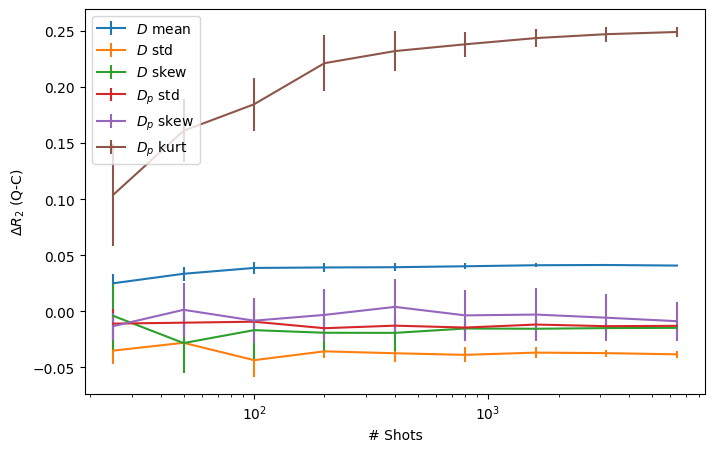

In [21]:
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
import numpy as np

# 1. Generate sample data
x = np.linspace(0, 10, 10)
fig, ax = plt.subplots(figsize=(8, 5))
labels = ["$D$ mean", "$D$ std", "$D$ skew", "$D$ kurt", "$D_p$ mean", "$D_p$ std", "$D_p$ skew", "$D_p$ kurt"]
# 2. Create the line plot with error bars
for i in [0,1,2,5,6,7]:
    ax.errorbar(shot_counts, shotsr2[i], yerr=shotsr2_std[i], label=labels[i])#, fmt='-o', capsize=4)#, ecolor='red')#, label=labels)


ax.set_xscale('log')

# 3. Add styling and show
ax.set_xlabel('# Shots')
ax.set_ylabel('$\\Delta R_2$ (Q-C)')
#plt.title('Line Plot with Error Bars')
ax.legend()
#plt.show()

In [22]:
shotsr2[7]


array([0.10380416, 0.16097401, 0.18458541, 0.22123183, 0.2320155 ,
       0.23807004, 0.24359726, 0.24707475, 0.24902742])